# Diabetes Health Indicators dataset: binary classification

**Task.** Predict whether a person has diabetes from health indicators collected by survey.

**Dataset.** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset (the copy used here is the one provided on Moodle).  
**Characteristics given in the assignment.** about 250,000 entries, 21 features, unbalanced classes.

This notebook applies the workflow implemented in `ml_workflow.py` to this dataset, shows the results and comments on them. It contains no machine-learning logic of its own: every step is a call to a function of the module. The second notebook of the project follows the same structure on the other dataset.

## Setup

Imports, configuration of the dataset and software environment.

In [1]:
# Reload ml_workflow automatically whenever the file is edited.
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ml_workflow as mlw

In [6]:
# Dataset
DATASET_NAME = "DHI"
DATA_PATH = Path("datasets") / "dbh" / "diabetes_binary_health_indicators_BRFSS2015.csv"
TARGET_COLUMN = "Diabetes_binary"

# Reproducibility
RANDOM_STATE = mlw.RANDOM_STATE

# Display
pd.set_option("display.max_columns", None)

In [11]:
# TODO: record the software environment that produced the results.
mlw.get_environment_info()

{'python': '3.13.9',
 'numpy': '2.3.5',
 'pandas': '2.3.3',
 'scikit-learn': '1.7.2',
 'matplotlib': '3.10.6',
 'seaborn': '0.13.2'}

## 1. Import the dataset

Load the file and separate the features from the target.

In [8]:
X, y = mlw.load_dataset(DATASET_NAME, DATA_PATH, TARGET_COLUMN)

## 2. Clean and pre-process

Understand the data, clean it, and decide how it will be pre-processed.

### 2.1 Exploration

Size, feature types, missing values, class balance and correlations. This is where the specific difficulties of the dataset are identified.

,count,mean,std,min,25%,50%,75%,max,dtype,missing
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0,float64,0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0,float64,0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0,float64,0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0,float64,0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0,float64,0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0,float64,0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0,float64,0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0,float64,0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0,float64,0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0,float64,0


,count,proportion
Diabetes_binary,,
0.0,218334,0.860667
1.0,35346,0.139333


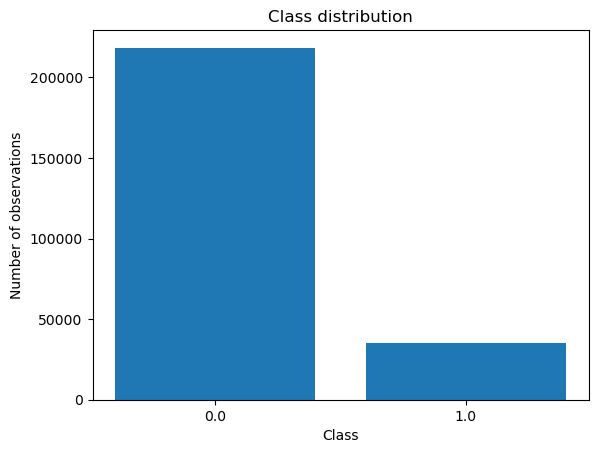

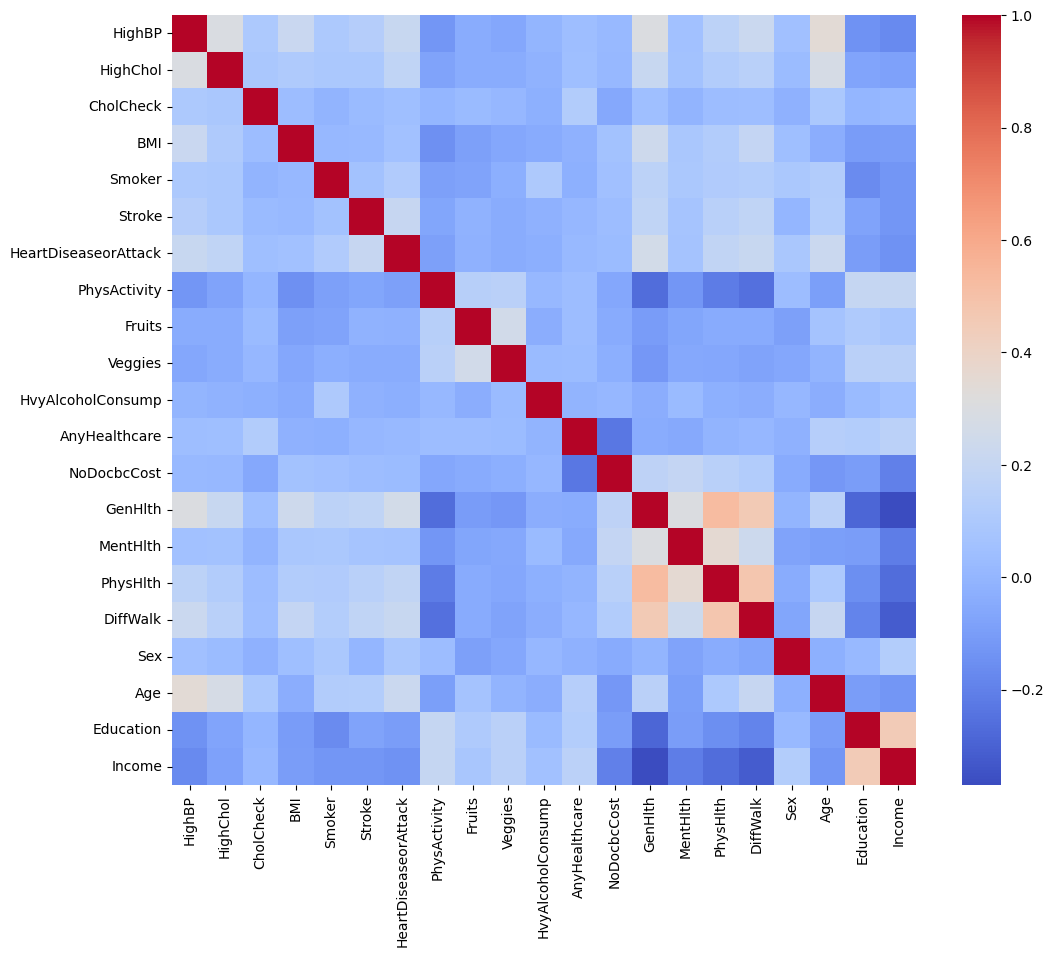

In [9]:
# TODO: explore the dataset.
#   mlw.summarize_dataset(X)
#   mlw.get_class_distribution(y)
#   mlw.plot_class_distribution(y)
#   mlw.plot_correlation_matrix(X)

# Dataset summary
display(mlw.summarize_dataset(X))

# Class distribution
display(mlw.get_class_distribution(y))

# Class distribution plot
mlw.plot_class_distribution(y)
plt.show()

# Correlation matrix
mlw.plot_correlation_matrix(X)
plt.show()

**Comments.** _TODO: interpret the results above._

### 2.2 Cleaning

Operations that learn nothing from the data (type conversion, duplicate rows, rows without a label), so they can safely run before the split.

In [ ]:
# TODO: clean the dataset.
#   X, y = mlw.clean_dataset(X, y)

**Comments.** _TODO: interpret the results above._

### 2.3 Pre-processing choices

Replacement of missing values (mean or median), centring and normalisation, and PCA.

These steps learn statistics from the data. To keep the test set unseen, they are only *chosen* here: they are *fitted* later, on the training set alone, as steps of the model pipeline (section 4).

In [ ]:
# TODO: choose the pre-processing options for this dataset.
#   IMPUTE_STRATEGY = ...  # "median" or "mean"

## 3. Split into training and test sets

Stratified split with a fixed seed. The test set is not used again before section 5.

In [ ]:
# TODO: split the dataset.
#   X_train, X_test, y_train, y_test = mlw.split_dataset(
#       X, y, random_state=RANDOM_STATE
#   )

## 4. Train the models

Everything in this section uses the training set only.

### 4.1 Principal component analysis

Variance explained by the principal components, to decide whether PCA is useful here and how many components to keep.

In [ ]:
# TODO: analyse the principal components of the training set.
#   mlw.plot_pca_explained_variance(X_train)
#   PCA_COMPONENTS = ...

**Comments.** _TODO: interpret the results above._

### 4.2 Feature selection

Rank the features, then choose the selection method and the number of features to keep.

In [ ]:
# TODO: score the features and configure the selector.
#   scores = mlw.compute_feature_scores(X_train, y_train)
#   mlw.plot_feature_scores(scores)
#   selector = mlw.build_feature_selector(...)

**Comments.** _TODO: interpret the results above._

### 4.3 Models and pipelines

Candidate classifiers, each wrapped in the same pipeline: imputation, scaling, feature selection, PCA, classifier.

In [ ]:
# TODO: build one pipeline per candidate model.
#   models = mlw.get_models(random_state=RANDOM_STATE)
#   pipelines = {
#       name: mlw.build_pipeline(model, selector=selector)
#       for name, model in models.items()
#   }

### 4.4 Cross-validation and hyper-parameter tuning

Compare the models on identical folds of the training set and tune their hyper-parameters, using the metric chosen for this dataset.

In [ ]:
# TODO: cross-validate and tune every pipeline.
#   SCORING = ...  # metric suited to this dataset
#   cv = mlw.build_cv_splitter(random_state=RANDOM_STATE)
#   mlw.cross_validate_model(pipeline, X_train, y_train, SCORING, cv)
#   mlw.tune_hyperparameters(
#       pipeline, mlw.get_param_grids()[name], X_train, y_train, SCORING, cv
#   )

**Comments.** _TODO: interpret the results above._

### 4.5 Final training

Fit each tuned pipeline on the whole training set.

In [ ]:
# TODO: fit the final models.
#   fitted_models = {
#       name: mlw.train_model(pipeline, X_train, y_train)
#       for name, pipeline in pipelines.items()
#   }

## 5. Validate the models

Performance of the final models on the test set, which they have never seen.

### 5.1 Metrics

One row per model, one column per metric.

In [ ]:
# TODO: compare the models on the test set.
#   results = mlw.compare_models(fitted_models, X_test, y_test)
#   mlw.plot_model_comparison(results, metric=SCORING)

**Comments.** _TODO: interpret the results above._

### 5.2 Confusion matrices

Kinds of errors made by each model.

In [ ]:
# TODO: plot one confusion matrix per model.
#   fig, axes = plt.subplots(1, len(fitted_models))
#   mlw.plot_confusion_matrix(model, X_test, y_test, ax=ax)

**Comments.** _TODO: interpret the results above._

### 5.3 ROC and precision-recall curves

Behaviour of each model over all decision thresholds.

In [ ]:
# TODO: plot the curves of all models.
#   mlw.plot_roc_curves(fitted_models, X_test, y_test)
#   mlw.plot_precision_recall_curves(fitted_models, X_test, y_test)

**Comments.** _TODO: interpret the results above._

## 6. Discussion and conclusion

_TODO: summarise the comparison, state which method is chosen for this dataset and why, and note the limits of the study._

## 7. AI usage statement

The project-wide statement on where, how and why AI tools were used is in `README.md`.

_TODO: add anything specific to this notebook._